# 3.5 — Contrast criterion example

Contrast measures global grayscale spread using population standard deviation
(`ddof=0`) and the linearly interpolated 95th minus 5th percentile.
It also reports near-black and near-white fractions. Global spread does not
establish subject/background separation or aesthetic quality.

**Interface:** dictionary settings → `ContrastCriterion.analyze(AnalysisInput(image))` → result dictionary.

No brand scores or acceptance thresholds are applied. Synthetic examples require no downloads.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from PIL import Image

In [2]:
from brandlens.analysis.analysis_input import AnalysisInput
from brandlens.analysis.contrast_criterion import ContrastCriterion

criterion = ContrastCriterion()
print("Resolved settings:", criterion.settings)

Resolved settings: {'near_black_max': 10, 'near_white_min': 245}


## Synthetic examples

Compare the images with their grayscale histograms. These RGB images are interpreted
as sRGB and can be used directly. Real photographs need the existing standardizer.

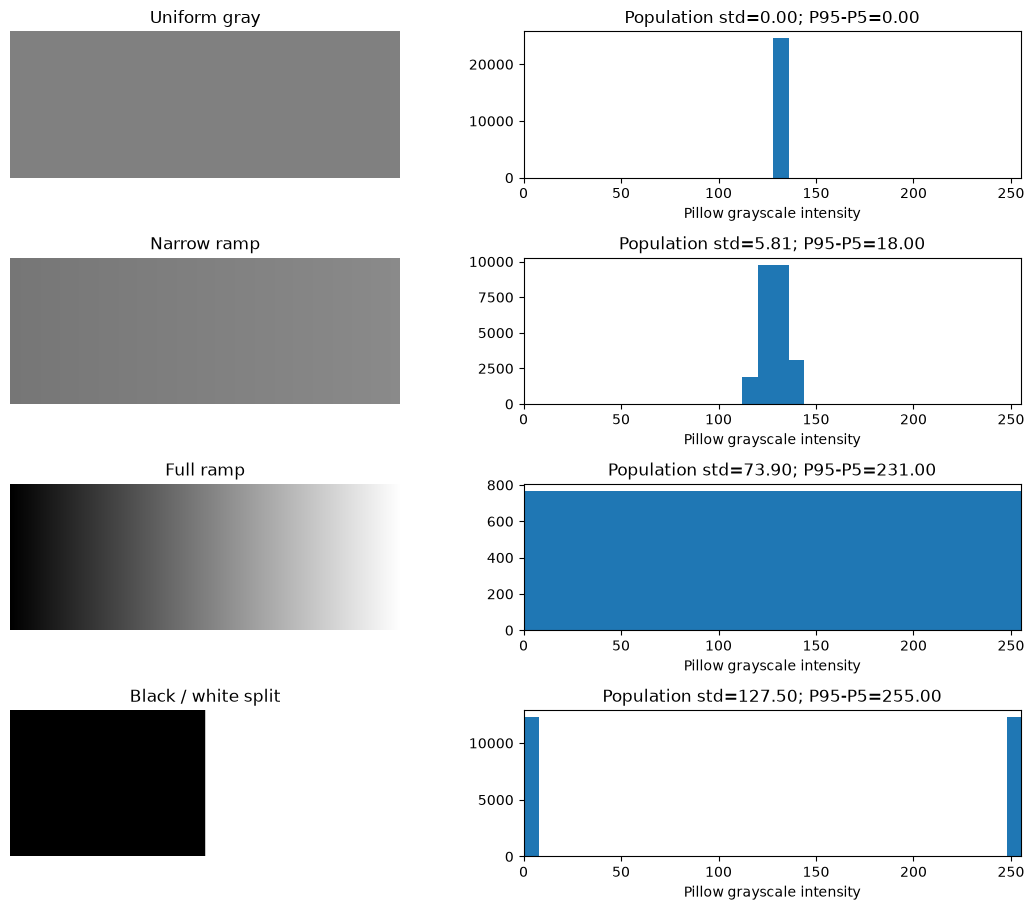

In [3]:
ramp = np.tile(np.arange(256, dtype=np.uint8), (96, 1))
low = np.tile(np.rint(np.linspace(118, 138, 256)).astype(np.uint8), (96, 1))
split = np.zeros_like(ramp)
split[:, 128:] = 255
images = {
    "Uniform gray": Image.new("RGB", (256, 96), (128, 128, 128)),
    "Narrow ramp": Image.fromarray(low).convert("RGB"),
    "Full ramp": Image.fromarray(ramp).convert("RGB"),
    "Black / white split": Image.fromarray(split).convert("RGB"),
}
results = {}
fig, axes = plt.subplots(len(images), 2, figsize=(11, 2.3 * len(images)))
for row, (name, image) in enumerate(images.items()):
    result = criterion.analyze(AnalysisInput(image))
    results[name] = result
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(name)
    axes[row, 0].axis("off")
    with image.convert("L") as gray:
        axes[row, 1].hist(np.asarray(gray).ravel(), bins=32, range=(0, 256))
    axes[row, 1].set_xlim(0, 255)
    axes[row, 1].set_xlabel("Pillow grayscale intensity")
    c = result["measurements"]
    axes[row, 1].set_title(
        f"Population std={c['luminance_std']:.2f}; P95-P5={c['p5_p95_range']:.2f}"
    )
fig.tight_layout()
plt.show()

## Inspect the result dictionary

`status="available"` means the measurement is computable, not that the image passes.
`method.parameters` records the resolved settings. `units` describes the measurement
scales. `reasons` explains unavailable measurements when a criterion supports that case.
This local result format is not yet an adapter for the project's HTTP API.

In [4]:
example_name = next(iter(results))
print(example_name)
print(json.dumps(results[example_name], indent=2, allow_nan=False))

Uniform gray
{
  "schema_version": "1.0.0",
  "criterion_id": "contrast",
  "status": "available",
  "measurements": {
    "luminance_std": 0.0,
    "p5_p95_range": 0.0,
    "near_black_fraction": 0.0,
    "near_white_fraction": 0.0
  },
  "method": {
    "id": "pillow_grayscale_contrast",
    "version": "1",
    "parameters": {
      "near_black_max": 10,
      "near_white_min": 245
    }
  },
  "units": {
    "luminance_std": "grayscale_0_255",
    "p5_p95_range": "grayscale_0_255",
    "near_black_fraction": "fraction_0_1",
    "near_white_fraction": "fraction_0_1"
  },
  "reasons": []
}


## Check known numerical outcomes

These assertions demonstrate measurement definitions on controlled inputs.

In [5]:
assert results["Uniform gray"]["measurements"]["luminance_std"] == 0.0
assert results["Uniform gray"]["measurements"]["p5_p95_range"] == 0.0
assert results["Black / white split"]["measurements"]["luminance_std"] == 127.5
assert results["Black / white split"]["measurements"]["p5_p95_range"] == 255.0
with Image.new("RGB", (4, 1)) as small:
    small.putdata([(v, v, v) for v in (0, 10, 20, 30)])
    m = criterion.analyze(AnalysisInput(small))["measurements"]
    assert np.isclose(m["luminance_std"], np.sqrt(125))
    assert np.isclose(m["p5_p95_range"], 27.0)
# Percentile interpolation depends on sample size: two pixels yield 229.5, not 255.
with Image.new("RGB", (2, 1)) as pair:
    pair.putdata([(0, 0, 0), (255, 255, 255)])
    assert (
        criterion.analyze(AnalysisInput(pair))["measurements"]["p5_p95_range"] == 229.5
    )
print("Population std and linear percentiles verified.")

Population std and linear percentiles verified.


## Dictionary settings and inclusive boundaries

A partial dictionary overrides only supplied defaults. These settings determine what
gets counted; they are not brand pass/fail limits. Create a new criterion to change settings.

In [6]:
custom = ContrastCriterion({"near_black_max": 11, "near_white_min": 244})
partial = ContrastCriterion({"near_black_max": 20})
print("Partial override:", partial.settings)
with Image.new("RGB", (6, 1)) as boundaries:
    boundaries.putdata([(v, v, v) for v in (0, 10, 11, 244, 245, 255)])
    data = AnalysisInput(boundaries)
    default_result = criterion.analyze(data)["measurements"]
    custom_result = custom.analyze(data)["measurements"]
print("Default:", default_result)
print("Custom: ", custom_result)
assert default_result["near_black_fraction"] == 1 / 3
assert custom_result["near_black_fraction"] == 0.5
assert custom_result["near_white_fraction"] == 0.5
# Accessing settings returns a copy, so this cannot alter the instance.
snapshot = custom.settings
snapshot["near_black_max"] = -1
assert custom.settings["near_black_max"] == 11

Partial override: {'near_black_max': 20, 'near_white_min': 245}
Default: {'luminance_std': 120.60230788283724, 'p5_p95_range': 250.0, 'near_black_fraction': 0.3333333333333333, 'near_white_fraction': 0.3333333333333333}
Custom:  {'luminance_std': 120.60230788283724, 'p5_p95_range': 250.0, 'near_black_fraction': 0.5, 'near_white_fraction': 0.5}


## Optional real photograph

Set a path below. This section uses your existing `standardize_image()` for EXIF
orientation, sRGB conversion and transparency handling. Merely calling `.convert("RGB")`
is not a replacement for color-profile standardization. Default standardization retains
resolution; measurement results can depend on preprocessing choices.

In [7]:
photo_path = None  # Example: repo_root / "data" / "example.jpg"
if photo_path is not None:
    from brandlens.preprocessing.standardization import standardize_image

    with Image.open(photo_path) as original:
        standardized = standardize_image(original)
    try:
        display(standardized)
        result = criterion.analyze(AnalysisInput(standardized))
        print(json.dumps(result, indent=2, allow_nan=False))
    finally:
        standardized.close()
else:
    print("Optional real-photo section skipped; set photo_path to run it.")

Optional real-photo section skipped; set photo_path to run it.


## Next integration step

A caller can put multiple criterion objects in a list and call `analyze(data)` on each.
Each returns the same outer structure with different measurements. Brand evaluation
should consume these measurements separately. Changing an algorithm may require
recalibration even if its result keys remain the same.